# Average U.S. Statutory Tariff Rate

Plots the daily statutory tariff series in `tariff_data.csv` and saves the figure as PNG/PDF in this folder.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    'axes.spines.top':   False,
    'axes.spines.right': False,
    'axes.linewidth':    8,
    'axes.labelweight':  'normal',
    'axes.titleweight':  'normal',
    'axes.titlesize':    18,
    'axes.labelsize':    16,
    'xtick.labelsize':   16,
    'ytick.labelsize':   16,
    'legend.frameon':    False,
    'legend.fontsize':   12,
    'grid.alpha':        0.3,
    'grid.linestyle':    '--',
    'savefig.bbox':      'tight',
})

PALETTE = {
    'aggregate':  'black',
    'primary':    '#2E5090',
    'secondary':  '#8B0000',
    'tertiary':   'darkgreen',
}

In [2]:
df = pd.read_csv('tariff_data.csv', parse_dates=['Date']).sort_values('Date').reset_index(drop=True)
print('Countries :', df['Country'].unique())
print('Metrics   :', df['Metric'].unique())
print('Date range:', df['Date'].min().date(), '->', df['Date'].max().date())
print('Value range: {:.2f}% -> {:.2f}%'.format(df['Value'].min(), df['Value'].max()))
df.head()

Countries : ['ALL COUNTRIES']
Metrics   : ['Statutory Tariff']
Date range: 2024-01-01 -> 2026-06-30
Value range: 2.52% -> 31.42%


,Country,Date,Metric,Value
0,ALL COUNTRIES,2024-01-01,Statutory Tariff,2.537944
1,ALL COUNTRIES,2024-01-02,Statutory Tariff,2.537944
2,ALL COUNTRIES,2024-01-03,Statutory Tariff,2.537944
3,ALL COUNTRIES,2024-01-04,Statutory Tariff,2.537944
4,ALL COUNTRIES,2024-01-05,Statutory Tariff,2.537944


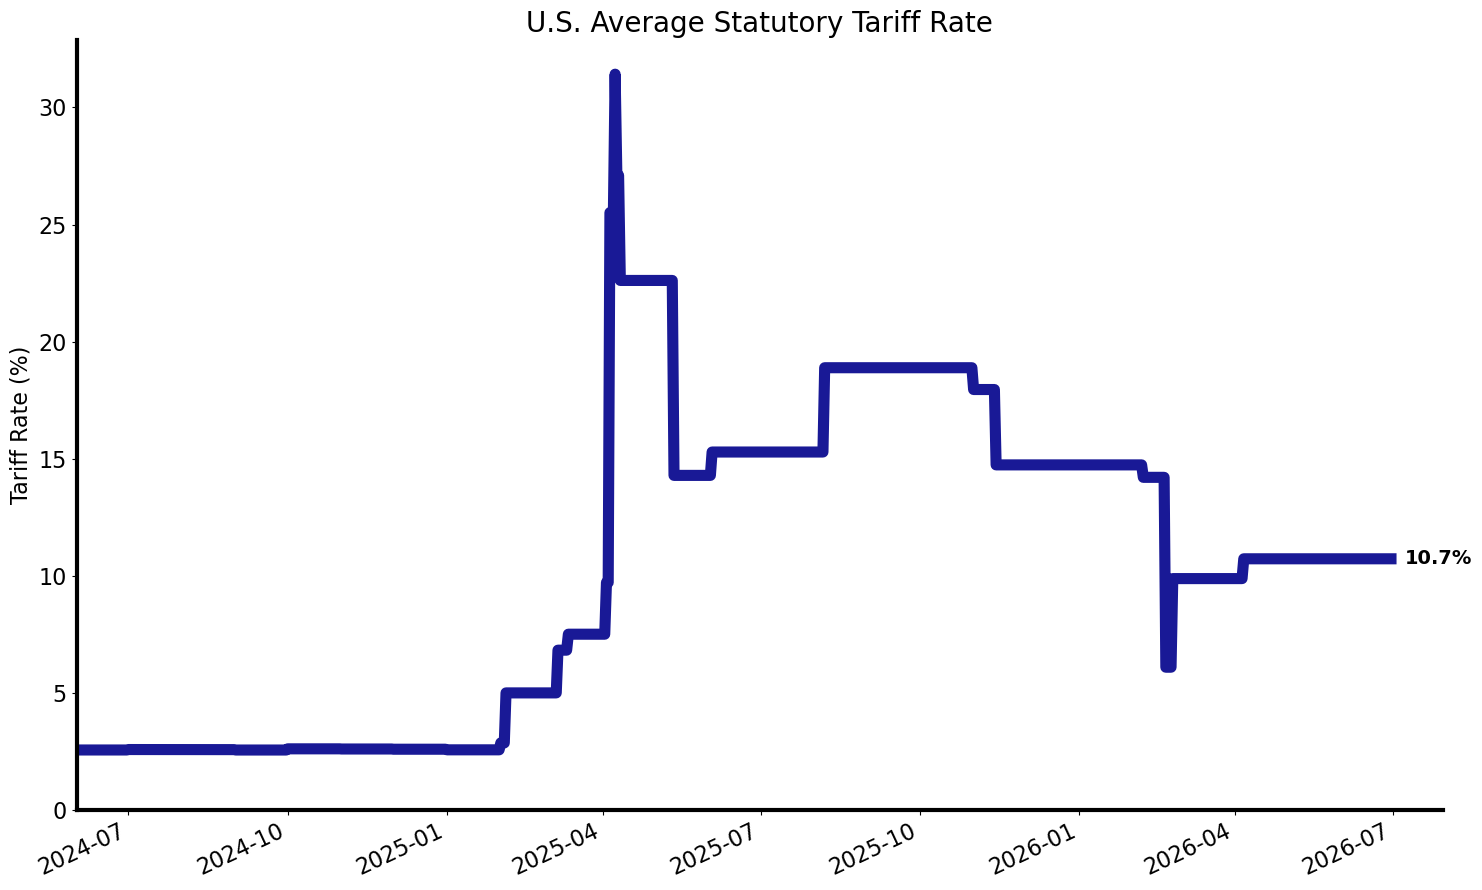

In [3]:
fig, ax = plt.subplots(figsize=(15, 9))
line_color = PALETTE['primary']

ax.plot(df['Date'], df['Value'], color="darkblue", linewidth=8, alpha=0.9)

# end-of-line value annotation
last_date = df['Date'].iloc[-1]
last_val  = df['Value'].iloc[-1]
ax.annotate(f'{last_val:.1f}%',
            xy=(last_date, last_val),
            xytext=(10, 0), textcoords='offset points',
            fontsize=14, fontweight='bold', color="black",
            va='center')

ax.set_title('U.S. Average Statutory Tariff Rate', fontsize=20)
ax.set_ylabel('Tariff Rate (%)', fontsize=16)
ax.set_xlabel('')

ax.spines['left'].set_linewidth(3)
ax.spines['bottom'].set_linewidth(3)

# year-month x-tick labels — rotate per style guide
plt.setp(ax.get_xticklabels(), rotation=25, ha='right')

# pad right edge so the end-of-line label doesn't clip
start_date = "2024-06-01"
start_date = pd.to_datetime(start_date)
ax.set_xlim([start_date, last_date + pd.Timedelta(days=30)])
ax.set_ylim(bottom=0)

plt.tight_layout()
plt.savefig('average-tariffs.png', bbox_inches='tight', dpi=150)
plt.savefig('average-tariffs.pdf', bbox_inches='tight')
plt.show()